# Single Retrieval Forward Vs Obs

In [1]:
# conda vis2
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np
from figs_to_html import figs_to_html

PROJECT_ROOT = Path().resolve().parent.parent
sys.path.append(str(PROJECT_ROOT))

plt.style.use('seaborn-v0_8-paper')

In [2]:
import src.Retrieval as retrieval
from src.ExperimentSet import ExperimentSet
from src.utils.util import set_labels

In [3]:
def get_pixels(r, i):
    misr = r.obs['MISR']['sensor_list'][i]
    at3d = r.sensors_retrieval['MISR']['sensor_list'][i]
    x = misr.ray_x.data
    y = misr.ray_y.data
    m = misr.brf.data
    a = at3d.brf.data
    return misr, at3d, x, y, m, a

def plot_F_vs_MISR(f, ax, r, plot_kwargs, diff_kwargs, contr_kwargs, contr=True, dom_boarder=False):

    for i in range(9):
        (misr, at3d, x, y, m, a) = get_pixels(r, i)
        ax[0,i].tricontourf(x, y, m, **plot_kwargs)
        c1 = ax[1,i].tricontourf(x, y, a, **plot_kwargs)
        c2 = ax[2, i].tricontourf(x, y, a-m, **diff_kwargs)
        # c2 = ax[2, i].tricontourf(x, y, 100*(a-m)/m, **diff_kwargs)
        if(contr):
            ax[0, i].tricontour(x, y, a-m, **contr_kwargs)
            ax[1, i].tricontour(x, y, a-m, **contr_kwargs)
            ax[2, i].tricontour(x, y, a-m, colors='k', levels=contr_kwargs['levels'])
        ax[0,i].set_title(misr.name)
        ax[2,i].set_xlabel('x (km)')

    # plt.colorbar(c1, ax=ax[0:2, :], label='BRF', shrink=0.8, ticks=[0.0, 0.1, 0.2, 0.3, 0.4])
    # plt.colorbar(c2, ax=ax[2,:], label='BRF Difference', shrink=0.8, ticks=[diff_kwargs['vmin'], 0.0, diff_kwargs['vmax']])
    # Two stacked colorbars in the right margin
    # [left, bottom, width, height] in figure-fraction coords
    cax1 = f.add_axes([0.88, 0.55, 0.016, 0.33])  # top: BRF
    cax2 = f.add_axes([0.88, 0.12, 0.016, 0.33])  # bottom: difference
    # cax1 = f.add_axes([0.12, 0.12, 0.33, 0.02])  # left: BRF
    # cax2 = f.add_axes([0.55, 0.12, 0.33, 0.02])  # right: difference
    f.colorbar(c1, cax=cax1, label='BRF',
            ticks=[0.0, 0.1, 0.2, 0.3, 0.4])
    f.colorbar(c2, cax=cax2, label='BRF Difference',
            ticks=[diff_kwargs['vmin'], 0.0, diff_kwargs['vmax']])
    
    plt.suptitle(f'{str(r.exp_name)}')
    ax[0, 0].set_ylabel('MISR\ny (km)')
    ax[1, 0].set_ylabel('AT3D\ny (km)')
    ax[2, 0].set_ylabel('AT3D - MISR\ny (km)')
    ticks = [0.0, 4.4, 8.8, 13.2, 17.6]
    box_kwargs = {'ls':'--', 'lw':0.7, 'c':'r'}
    for a in ax.flat:
        if(dom_boarder):
            a.plot([0, 0], [0, 17.6], **box_kwargs)
            a.plot([0, 17.6], [0, 0], **box_kwargs)
            a.plot([17.6, 17.6], [0, 17.6], **box_kwargs)
            a.plot([0, 17.6], [17.6, 17.6], **box_kwargs)
        a.set_xticks(ticks)
        a.set_xticklabels(ticks, rotation=45)
        a.set_yticks(ticks)

vrange = 0.18
# vrange = 100
plot_kwargs = {
    'cmap':'gray',
    'vmin':0,
    'vmax':0.4,
    'levels':np.linspace(0, 0.4, 50)
}
diff_kwargs = {
    'cmap':'RdBu_r',
    'vmin':-vrange,
    'vmax':vrange,
    'levels':np.linspace(-vrange, vrange, 100)
}
contr_kwargs = diff_kwargs.copy()
contr_kwargs['levels'] = np.array([0.05])

In [4]:
es_dir = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V11'
exset = ExperimentSet(es_dir)
exset.set_retrieval_list()
exset.load_retrievals(iteration=-1, extinction_th=[0.3, np.inf])

In [5]:
r = exset.get_retrieval('default')

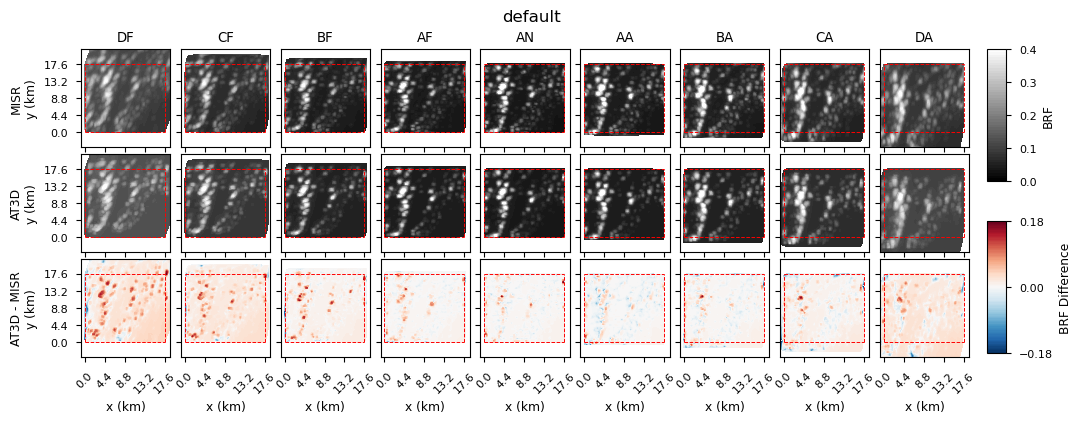

In [6]:
f, ax = plt.subplots(3, 9, figsize=(12, 4), sharex=True, sharey=True)
plt.subplots_adjust(wspace=0.12, hspace=0.07, right=0.865)
plot_F_vs_MISR(f, ax, r, plot_kwargs, diff_kwargs, contr_kwargs, contr=False, dom_boarder=True)

In [7]:
figlist = []

sublist = ['default', 'unconstrained', 'default', 'surf4p0', 'aod0p150', 'default', 'aod0p250', 'default', 'periodic', 'ATM_unc', 'unconstrained', 'ATP_unc', 'CTM_unc', 'unconstrained', 'CTP_unc']

for rname in sublist:
    r = exset.get_retrieval(rname)
    f, ax = plt.subplots(3, 9, figsize=(12, 4), sharex=True, sharey=True)
    plt.subplots_adjust(wspace=0.12, hspace=0.07, right=0.865)
    plot_F_vs_MISR(f, ax, r, plot_kwargs, diff_kwargs, contr_kwargs, contr=False, dom_boarder=True)
    figlist.append(f)
    plt.close(f)

figs_to_html(figlist, es_dir / 'figures' / 'AT3D_VS_MISR.html', titles=sublist)

PosixPath('/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V11/figures/AT3D_VS_MISR.html')